In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
pollut1=pd.read_csv('../data/raw/Export_Moy_journaliere_Finistere - 2021-01-01 00_00 - 2026-10-27 14_00.csv', sep=';')

print(pollut1.shape)
print(pollut1['code zas'].unique())

(27223, 23)
<StringArray>
['FR53ZAR01', 'FR53ZRE01']
Length: 2, dtype: str


In [3]:
import requests
import json
import os

METRO_DEPTS = (
    {f"{i:02d}" for i in range(1, 20)}
    | {'2A', '2B'}
    | {f"{i:02d}" for i in range(21, 96)}
)

def get_departement(lat, lon):
    url = f"https://geo.api.gouv.fr/communes?lat={lat}&lon={lon}&fields=departement"
    r = requests.get(url)
    if r.ok and r.json():
        code = r.json()[0]['departement']['code']
        return code if code in METRO_DEPTS else None
    return None

# Chargement du cache existant
if os.path.exists('sites_dept.json'):
    with open('sites_dept.json') as f:
        resultats = json.load(f)
else:
    resultats = {}

sites = pollut1[['code site', 'Latitude', 'Longitude']].drop_duplicates('code site').reset_index(drop=True)
nouveaux = sites[~sites['code site'].isin(resultats)]

for i, row in nouveaux.iterrows():
    if i % 10 == 0:
        print(f"{i}/{len(nouveaux)}")
    resultats[row['code site']] = get_departement(row['Latitude'], row['Longitude'])

# Sauvegarde du cache
with open('sites_dept.json', 'w') as f:
    json.dump(resultats, f)

sites['code_dept'] = sites['code site'].map(resultats)
pollut = pollut1.merge(sites[['code site', 'code_dept']], on='code site', how='left')

In [4]:
display(pollut.head(5))
display(pollut.tail(5))

print(pollut.shape)
print(pollut['code_dept'].unique())
# Le dataset contient maintenant l'information nécessaire en chiffre et en lettre, placé tout à la fin du dataframe

,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,Latitude,Longitude,code_dept
0,2021/01/01 00:00:00,2021/01/01 23:59:59,AIR BREIZH,FR53ZAR01,ZAR BREST,FR19012,Brest Mace,Urbaine,NOX as NO2,Fond,...,28.433333,µg-m3,100.0,100,100.0,R,1,48.38618,-4.4866,29
1,2021/01/02 00:00:00,2021/01/02 23:59:59,AIR BREIZH,FR53ZAR01,ZAR BREST,FR19012,Brest Mace,Urbaine,NOX as NO2,Fond,...,18.966667,µg-m3,100.0,100,100.0,R,1,48.38618,-4.4866,29
2,2021/01/03 00:00:00,2021/01/03 23:59:59,AIR BREIZH,FR53ZAR01,ZAR BREST,FR19012,Brest Mace,Urbaine,NOX as NO2,Fond,...,16.704167,µg-m3,100.0,100,100.0,R,1,48.38618,-4.4866,29
3,2021/01/04 00:00:00,2021/01/04 23:59:59,AIR BREIZH,FR53ZAR01,ZAR BREST,FR19012,Brest Mace,Urbaine,NOX as NO2,Fond,...,28.650000,µg-m3,100.0,100,100.0,R,1,48.38618,-4.4866,29
4,2021/01/05 00:00:00,2021/01/05 23:59:59,AIR BREIZH,FR53ZAR01,ZAR BREST,FR19012,Brest Mace,Urbaine,NOX as NO2,Fond,...,28.120833,µg-m3,100.0,100,100.0,R,1,48.38618,-4.4866,29


,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,Latitude,Longitude,code_dept
27218,2026/10/23 00:00:00,2026/10/23 23:59:59,AIR BREIZH,FR53ZRE01,ZR BRETAGNE,FR19053,Quimper Zola,Urbaine,O3,Fond,...,77.745833,µg-m3,100.0,100,100.0,A,1,47.986606,-4.097658,29
27219,2026/10/24 00:00:00,2026/10/24 23:59:59,AIR BREIZH,FR53ZRE01,ZR BRETAGNE,FR19053,Quimper Zola,Urbaine,O3,Fond,...,75.820833,µg-m3,100.0,100,100.0,A,1,47.986606,-4.097658,29
27220,2026/10/25 00:00:00,2026/10/25 23:59:59,AIR BREIZH,FR53ZRE01,ZR BRETAGNE,FR19053,Quimper Zola,Urbaine,O3,Fond,...,68.116667,µg-m3,100.0,100,100.0,A,1,47.986606,-4.097658,29
27221,2026/10/26 00:00:00,2026/10/26 23:59:59,AIR BREIZH,FR53ZRE01,ZR BRETAGNE,FR19053,Quimper Zola,Urbaine,O3,Fond,...,63.321739,µg-m3,96.0,100,96.0,A,1,47.986606,-4.097658,29
27222,2026/10/27 00:00:00,2026/10/27 13:00:00,AIR BREIZH,FR53ZRE01,ZR BRETAGNE,FR19053,Quimper Zola,Urbaine,O3,Fond,...,69.907692,µg-m3,100.0,100,100.0,A,1,47.986606,-4.097658,29


(27223, 24)
<StringArray>
['29']
Length: 1, dtype: str


In [5]:
pollut = pollut.reset_index(drop=True)
pollut["jour"] = pd.to_datetime(pollut["Date de fin"]).dt.dayofyear 
pollut['valeur'] = pollut['valeur'].where(pollut['valeur'] >= 0)

print(pollut.isna().sum())
print(pollut["Polluant"].value_counts())

polluants=pollut["Polluant"].unique().tolist()

d=pollut[(pollut['jour']==355) & (pollut['Polluant']=='O3')]

print(f"Mesures / jour : {pollut.shape}")


Date de début            0
Date de fin              0
Organisme                0
code zas                 0
Zas                      0
code site                0
nom site                 0
type d'implantation      0
Polluant                 0
type d'influence         0
Réglementaire            0
type d'évaluation        0
type de valeur           0
valeur                   8
valeur brute             0
unité de mesure          0
taux de saisie           0
couverture temporelle    0
couverture de données    0
code qualité             0
validité                 0
Latitude                 0
Longitude                0
code_dept                0
jour                     0
dtype: int64
Polluant
O3            6341
NOX as NO2    5740
NO2           5740
PM10          5399
PM2.5         4003
Name: count, dtype: int64
Mesures / jour : (27223, 25)


type d'influence
Fond      21091
Trafic     6132
Name: count, dtype: int64


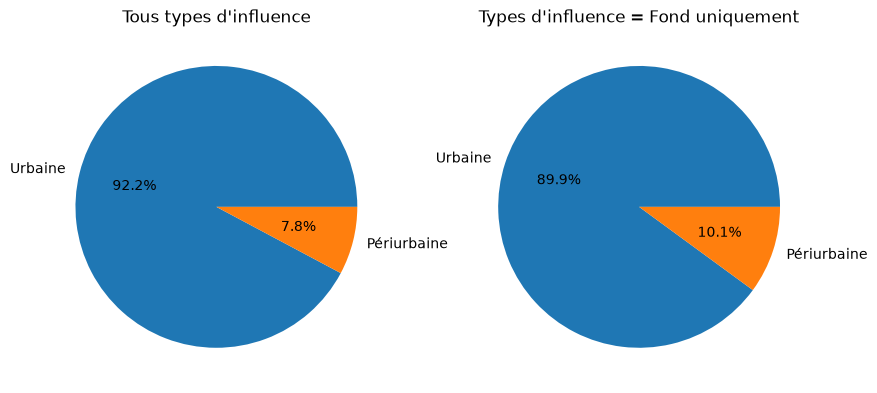

In [6]:


print(pollut["type d'influence"].value_counts())
pollut_avant = pollut.copy()
pollut = pollut[pollut["type d'influence"] == 'Fond']
#“Fond” donne le niveau de pollution de fond régional uniquement

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
categories = list(set(pollut_avant["type d'implantation"]).union(set(pollut["type d'implantation"])))
palette = plt.cm.tab10.colors
couleurs = {cat: palette[i] for i, cat in enumerate(categories)}

# Avant
counts_avant = pollut_avant["type d'implantation"].value_counts()
axes[0].pie(counts_avant.values,
            labels=counts_avant.index,
            colors=[couleurs[c] for c in counts_avant.index],
            autopct='%1.1f%%')
axes[0].set_title("Tous types d'influence")

#type d'implantation — distingue Urbaine, Rurale nationale, Rurale près des villes, etc. 
#Mieux équilibré après sélection de "Fond" régional uniquement

counts_apres = pollut["type d'implantation"].value_counts()
axes[1].pie(counts_apres.values,
            labels=counts_apres.index,
            colors=[couleurs[c] for c in counts_apres.index],
            autopct='%1.1f%%')
axes[1].set_title("Types d'influence = Fond uniquement")

plt.show()